Learned Q-table:
[[ 0.62  1.81  0.61  1.06]
 [-1.12 -4.25 -1.09  2.8 ]
 [-0.27  4.52 -1.08  0.02]
 [-0.6   3.86 -0.16 -0.58]
 [ 0.62  3.12  1.8  -7.18]
 [ 0.    0.    0.    0.  ]
 [ 1.05  2.7  -3.01  6.2 ]
 [ 0.28  8.    2.13  3.62]
 [ 1.79  4.38  3.08  4.58]
 [-4.42  6.08  3.08  6.2 ]
 [ 4.44  8.    4.54  7.79]
 [ 3.57 10.    3.06  4.54]
 [ 0.31  0.9   0.25  6.17]
 [ 1.98  4.33  1.69  8.  ]
 [ 6.17  7.98  6.13 10.  ]
 [ 0.    0.    0.    0.  ]]

Learned path: [0, 4, 8, 9, 10, 14, 15]
Reached goal: True


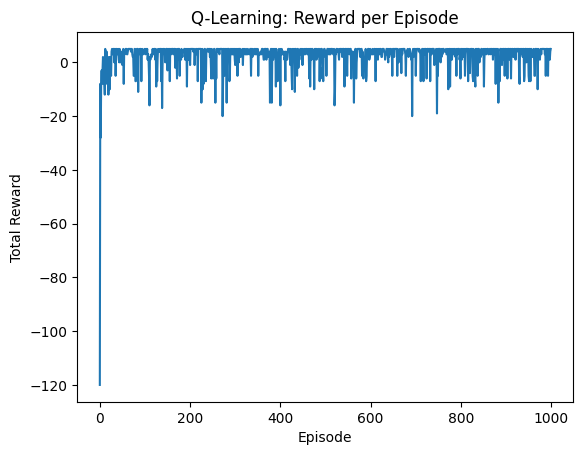

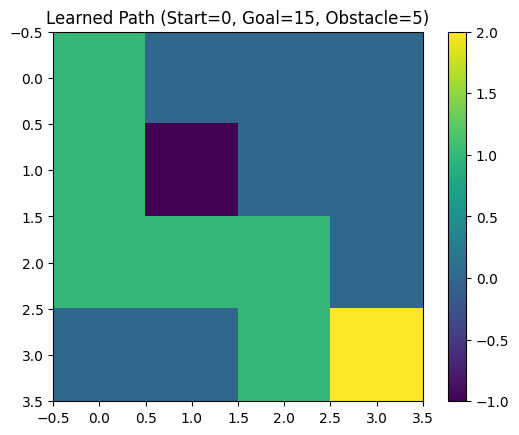

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Environment
rows, cols = 4, 4
states = rows * cols
actions = 4                  # 0=Up, 1=Down, 2=Left, 3=Right
goal = 15
obstacle = 5

Q = np.zeros((states, actions))

alpha = 0.1                  # Learning rate
gamma = 0.9                  # Discount factor
epsilon = 0.2                # Exploration probability
episodes = 1000

def move(state, action):
    r, c = divmod(state, cols)

    if action == 0:
        r = max(0, r - 1)
    elif action == 1:
        r = min(rows - 1, r + 1)
    elif action == 2:
        c = max(0, c - 1)
    else:
        c = min(cols - 1, c + 1)

    next_state = r * cols + c

    if next_state == obstacle:
        return state, -10, False

    if next_state == goal:
        return next_state, 10, True

    return next_state, -1, False

# 2. Train the agent
rewards = []

for episode in range(episodes):
    state = 0
    total_reward = 0

    for step in range(100):
        # Epsilon-greedy action selection
        if np.random.random() < epsilon:
            action = np.random.randint(actions)
        else:
            action = np.argmax(Q[state])

        next_state, reward, done = move(state, action)

        # Q-learning update
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) * (not done)
            - Q[state, action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    rewards.append(total_reward)

# 3. Display the learned Q-table
print("Learned Q-table:")
print(np.round(Q, 2))

# 4. Test the learned policy
state = 0
path = [state]

for _ in range(20):
    action = np.argmax(Q[state])
    next_state, reward, done = move(state, action)

    if next_state == state:
        break

    state = next_state
    path.append(state)

    if done:
        break

print("\nLearned path:", path)
print("Reached goal:", state == goal)

# 5. Plot rewards
plt.plot(rewards)
plt.title("Q-Learning: Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.show()

# 6. Visualize the path
grid = np.zeros((rows, cols))
grid.flat[obstacle] = -1
grid.flat[goal] = 2

for s in path:
    if s not in (goal, obstacle):
        grid.flat[s] = 1

plt.imshow(grid, cmap="viridis")
plt.title("Learned Path (Start=0, Goal=15, Obstacle=5)")
plt.colorbar()
plt.show()